<a href="https://colab.research.google.com/github/ayudewanti14/implementasi4/blob/main/implementasi4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Library siap dipakai.")

Library siap dipakai.


In [ ]:
n = 600
lokasi = np.random.choice(["Pusat Kota", "Pinggiran", "Pedesaan"], n, p=[0.3, 0.4, 0.3])
luas = np.random.randint(40, 300, n).astype(float)
kamar_tidur = np.random.randint(1, 6, n).astype(float)
kamar_mandi = np.random.randint(1, 4, n).astype(float)

faktor_lokasi = pd.Series(lokasi).map({"Pusat Kota": 1.6, "Pinggiran": 1.1, "Pedesaan": 0.7}).values
harga = (luas * 8 + kamar_tidur * 40 + kamar_mandi * 25) * faktor_lokasi + np.random.normal(0, 40, n)  # juta rupiah

df = pd.DataFrame({"luas_m2": luas, "kamar_tidur": kamar_tidur,
                   "kamar_mandi": kamar_mandi, "lokasi": lokasi, "harga_juta": harga})

# Sisipkan missing value dan duplikat
df.loc[np.random.choice(n, 25, replace=False), "luas_m2"] = np.nan
df.loc[np.random.choice(n, 20, replace=False), "kamar_mandi"] = np.nan
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

df.head()

,luas_m2,kamar_tidur,kamar_mandi,lokasi,harga_juta
0,44.0,2.0,2.0,Pinggiran,518.527549
1,131.0,3.0,3.0,Pedesaan,807.572368
2,209.0,2.0,1.0,Pedesaan,1279.224391
3,61.0,2.0,2.0,Pinggiran,676.686512
4,40.0,5.0,2.0,Pusat Kota,904.780803


In [ ]:
print("Bentuk data :", df.shape)
print("Duplikat    :", df.duplicated().sum())
print("\nMissing value per kolom:")
print(df.isna().sum())

df = df.drop_duplicates().reset_index(drop=True)
print("\nSetelah hapus duplikat:", df.shape)
df.describe()

Bentuk data : (601, 5)
Duplikat    : 1

Missing value per kolom:
luas_m2        25
kamar_tidur     0
kamar_mandi    20
lokasi          0
harga_juta      0
dtype: int64

Setelah hapus duplikat: (600, 5)


,luas_m2,kamar_tidur,kamar_mandi,harga_juta
count,575.000000,600.000000,580.000000,600.000000
mean,164.613913,3.016667,1.951724,1676.593138
std,76.549115,1.420006,0.804401,898.731785
min,40.000000,1.000000,1.000000,299.052419
25%,98.000000,2.000000,1.000000,961.006308
50%,165.000000,3.000000,2.000000,1525.297296
75%,232.000000,4.000000,3.000000,2259.644017
max,299.000000,5.000000,3.000000,4286.722312


In [ ]:
fitur_numerik = ["luas_m2", "kamar_tidur", "kamar_mandi"]
fitur_kategori = ["lokasi"]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), fitur_numerik),
    ("cat", OneHotEncoder(handle_unknown="ignore"), fitur_kategori),
])

In [ ]:
X = df.drop(columns="harga_juta")
y = df["harga_juta"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE)

print(f"Training  : {len(X_train)} baris")
print(f"Validation: {len(X_val)} baris")
print(f"Testing   : {len(X_test)} baris")

Training  : 420 baris
Validation: 90 baris
Testing   : 90 baris


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

kandidat = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
}

model_terlatih = {}
for nama, reg in kandidat.items():
    pipe = Pipeline([("prep", preprocess), ("model", reg)])
    pipe.fit(X_train, y_train)
    model_terlatih[nama] = pipe
print("Pelatihan selesai.")

Pelatihan selesai.


In [ ]:
def evaluasi_regresi(model, X_, y_):
    pred = model.predict(X_)
    return {"MAE": mean_absolute_error(y_, pred),
            "RMSE": np.sqrt(mean_squared_error(y_, pred)),
            "R2": r2_score(y_, pred)}

hasil = []
for nama, pipe in model_terlatih.items():
    tr = evaluasi_regresi(pipe, X_train, y_train)
    va = evaluasi_regresi(pipe, X_val, y_val)
    hasil.append({"Model": nama, "R2 train": tr["R2"], "R2 val": va["R2"],
                  "MAE val": va["MAE"], "RMSE val": va["RMSE"]})
pd.DataFrame(hasil).round(3)

,Model,R2 train,R2 val,MAE val,RMSE val
0,Linear Regression,0.911,0.957,132.994,198.010
1,Random Forest,0.990,0.985,70.569,115.423


Model terbaik: Random Forest
{'MAE': 113.165, 'RMSE': 232.102, 'R2': 0.94}


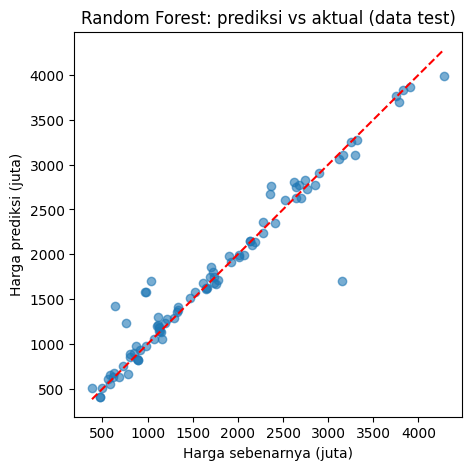

In [ ]:
# Pilih model terbaik berdasarkan R2 validation, lalu uji SEKALI pada data test
tabel = pd.DataFrame(hasil).set_index("Model")
terbaik = tabel["R2 val"].idxmax()
print("Model terbaik:", terbaik)

akhir = evaluasi_regresi(model_terlatih[terbaik], X_test, y_test)
print({k: round(float(v), 3) for k, v in akhir.items()})

pred_test = model_terlatih[terbaik].predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_test, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Harga sebenarnya (juta)")
plt.ylabel("Harga prediksi (juta)")
plt.title(f"{terbaik}: prediksi vs aktual (data test)")
plt.show()

In [ ]:
rumah_baru = pd.DataFrame([{"luas_m2": 120, "kamar_tidur": 3, "kamar_mandi": 2, "lokasi": "Pusat Kota"}])
estimasi = model_terlatih[terbaik].predict(rumah_baru)[0]
print(f"Estimasi harga: Rp {estimasi:,.0f} juta")

# Untuk menyimpan model:
# import joblib; joblib.dump(model_terlatih[terbaik], "model_harga_rumah.joblib")

Estimasi harga: Rp 1,962 juta


In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

data = load_breast_cancer()
Xc = pd.DataFrame(data.data, columns=data.feature_names)
yc = pd.Series(data.target, name="label")   # 0 = ganas, 1 = jinak

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

algoritma = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "k-NN": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM": SVC(),
}

baris, model_klasifikasi = [], {}
for nama, clf in algoritma.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", clf)])
    pipe.fit(Xc_train, yc_train)
    pred = pipe.predict(Xc_test)
    model_klasifikasi[nama] = pipe
    baris.append({
        "Algoritma": nama,
        "Accuracy": accuracy_score(yc_test, pred),
        "Precision": precision_score(yc_test, pred),
        "Recall": recall_score(yc_test, pred),
        "F1": f1_score(yc_test, pred),
        "CV 5-fold": cross_val_score(pipe, Xc, yc, cv=5).mean(),
    })

pd.DataFrame(baris).set_index("Algoritma").round(3).sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,CV 5-fold
Algoritma,,,,,
Logistic Regression,0.982,0.986,0.986,0.986,0.981
SVM,0.982,0.986,0.986,0.986,0.974
k-NN,0.956,0.959,0.972,0.966,0.965
Random Forest,0.956,0.959,0.972,0.966,0.958
Naive Bayes,0.930,0.944,0.944,0.944,0.928
Decision Tree,0.912,0.956,0.903,0.929,0.917


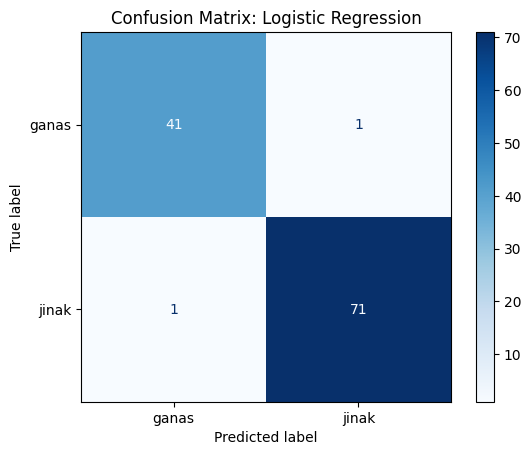

In [ ]:
terbaik_clf = pd.DataFrame(baris).set_index("Algoritma")["F1"].idxmax()
pred = model_klasifikasi[terbaik_clf].predict(Xc_test)

ConfusionMatrixDisplay(confusion_matrix(yc_test, pred),
                       display_labels=["ganas", "jinak"]).plot(cmap="Blues")
plt.title(f"Confusion Matrix: {terbaik_clf}")
plt.show()

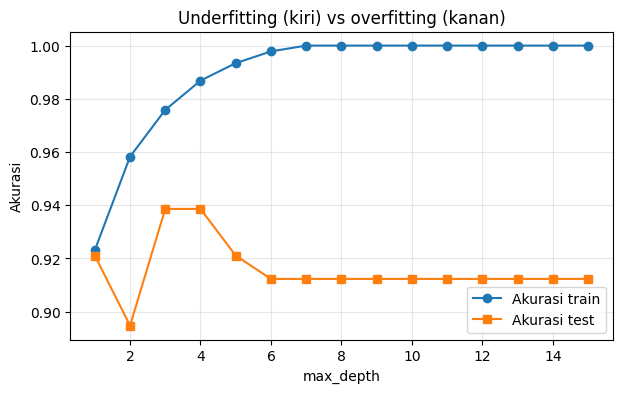

In [ ]:
kedalaman = range(1, 16)
acc_train, acc_test = [], []
for d in kedalaman:
    tree = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xc_train, yc_train)
    acc_train.append(tree.score(Xc_train, yc_train))
    acc_test.append(tree.score(Xc_test, yc_test))

plt.figure(figsize=(7, 4))
plt.plot(kedalaman, acc_train, "o-", label="Akurasi train")
plt.plot(kedalaman, acc_test, "s-", label="Akurasi test")
plt.xlabel("max_depth")
plt.ylabel("Akurasi")
plt.title("Underfitting (kiri) vs overfitting (kanan)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

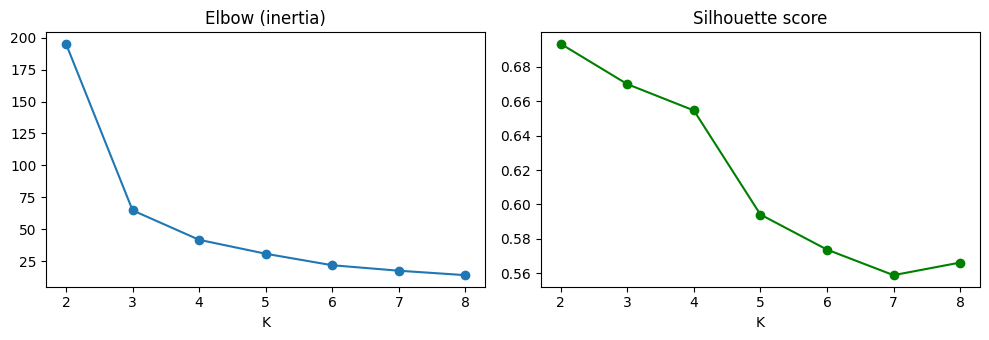

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA

pusat = [[5, 150], [30, 400], [12, 300], [50, 900]]   # [frekuensi/bulan, belanja rata-rata (ribu)]
Xp, _ = make_blobs(n_samples=400, centers=pusat, cluster_std=[3, 8, 5, 8], random_state=RANDOM_STATE)
pelanggan = pd.DataFrame(Xp, columns=["frekuensi_belanja", "rata_rata_belanja_ribu"])
Xp_scaled = StandardScaler().fit_transform(pelanggan)

inertia, sil = [], []
rentang_k = range(2, 9)
for k in rentang_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xp_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xp_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rentang_k, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("K")
ax[1].plot(rentang_k, sil, "o-", color="green"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("K")
plt.tight_layout(); plt.show()

Silhouette score: 0.655
         frekuensi_belanja  rata_rata_belanja_ribu  jumlah
cluster                                                   
0                     32.6                   399.4      91
1                     49.4                   900.8     100
2                      4.5                   155.8     104
3                     12.4                   308.9     105


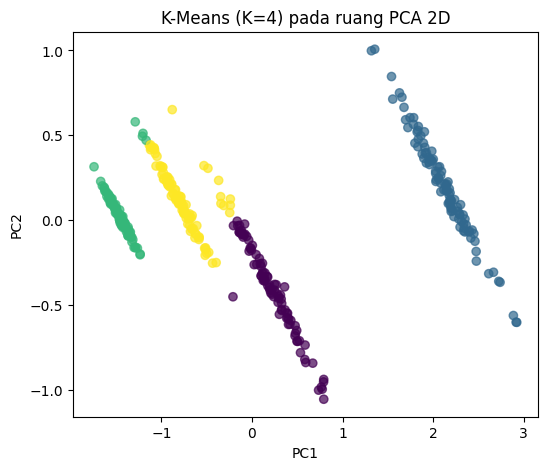

In [14]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xp_scaled)
pelanggan["cluster"] = km.labels_
print("Silhouette score:", round(silhouette_score(Xp_scaled, km.labels_), 3))

# Interpretasi cluster
profil = pelanggan.groupby("cluster").mean().round(1)
profil["jumlah"] = pelanggan["cluster"].value_counts().sort_index()
print(profil)

# Visualisasi 2D dengan PCA
pca = PCA(n_components=2)
Z = pca.fit_transform(Xp_scaled)
plt.figure(figsize=(6, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="viridis", alpha=0.7)
plt.title(f"K-Means (K={K}) pada ruang PCA 2D")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

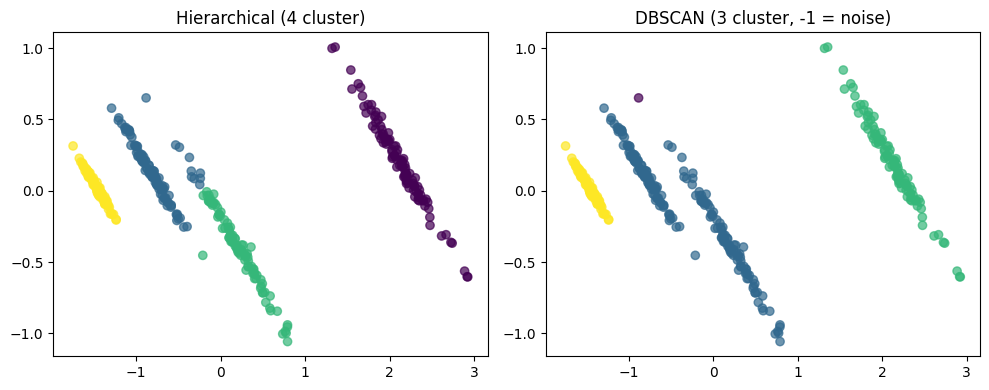

In [15]:
hier = AgglomerativeClustering(n_clusters=4).fit_predict(Xp_scaled)
dbscan = DBSCAN(eps=0.3, min_samples=5).fit_predict(Xp_scaled)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(Z[:, 0], Z[:, 1], c=hier, cmap="viridis", alpha=0.7); ax[0].set_title("Hierarchical (4 cluster)")
ax[1].scatter(Z[:, 0], Z[:, 1], c=dbscan, cmap="viridis", alpha=0.7)
ax[1].set_title(f"DBSCAN ({len(set(dbscan)) - (1 if -1 in dbscan else 0)} cluster, -1 = noise)")
plt.tight_layout(); plt.show()

10 dari 30 komponen sudah menjelaskan >= 95% variansi.


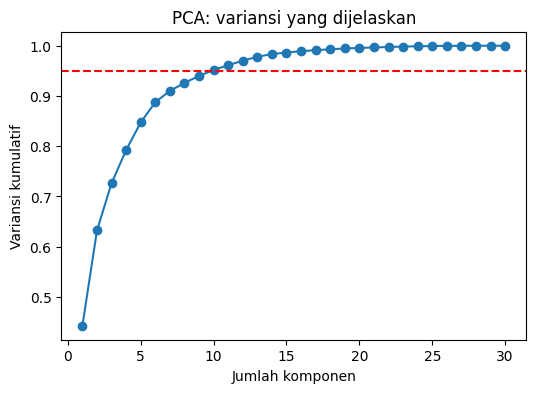

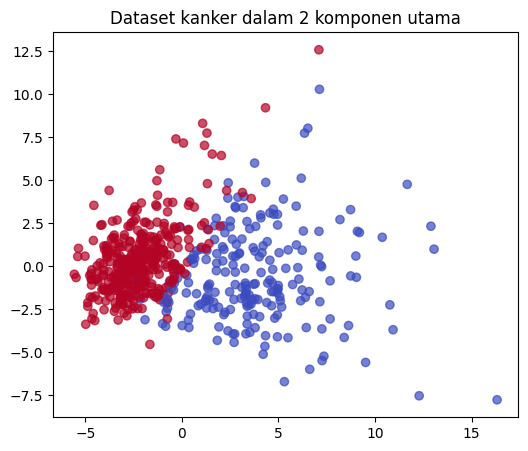

In [16]:
Xc_scaled = StandardScaler().fit_transform(Xc)
pca_full = PCA().fit(Xc_scaled)
kumulatif = np.cumsum(pca_full.explained_variance_ratio_)
n_95 = int(np.argmax(kumulatif >= 0.95) + 1)
print(f"{n_95} dari 30 komponen sudah menjelaskan >= 95% variansi.")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 31), kumulatif, "o-")
plt.axhline(0.95, color="r", linestyle="--")
plt.xlabel("Jumlah komponen"); plt.ylabel("Variansi kumulatif")
plt.title("PCA: variansi yang dijelaskan")
plt.show()

# Tampilkan data dalam 2D, diwarnai label asli
Z2 = PCA(n_components=2).fit_transform(Xc_scaled)
plt.figure(figsize=(6, 5))
plt.scatter(Z2[:, 0], Z2[:, 1], c=yc, cmap="coolwarm", alpha=0.7)
plt.title("Dataset kanker dalam 2 komponen utama")
plt.show()

Transaksi terdeteksi anomali: 20 dari 500


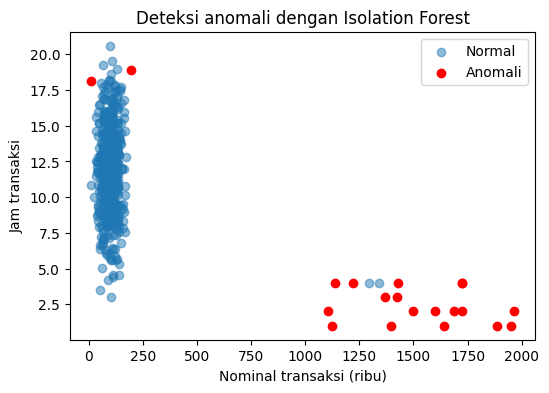

In [17]:
from sklearn.ensemble import IsolationForest

normal = np.random.normal(loc=[100, 12], scale=[30, 3], size=(480, 2))     # [nominal (ribu), jam]
fraud = np.column_stack([np.random.uniform(900, 2000, 20), np.random.choice([1, 2, 3, 4], 20)])
transaksi = np.vstack([normal, fraud])

iso = IsolationForest(contamination=0.04, random_state=RANDOM_STATE).fit(transaksi)
label = iso.predict(transaksi)           # 1 = normal, -1 = anomali
print("Transaksi terdeteksi anomali:", (label == -1).sum(), "dari", len(transaksi))

plt.figure(figsize=(6, 4))
plt.scatter(transaksi[label == 1, 0], transaksi[label == 1, 1], alpha=0.5, label="Normal")
plt.scatter(transaksi[label == -1, 0], transaksi[label == -1, 1], c="red", label="Anomali")
plt.xlabel("Nominal transaksi (ribu)"); plt.ylabel("Jam transaksi")
plt.legend(); plt.title("Deteksi anomali dengan Isolation Forest")
plt.show()

In [18]:
from itertools import combinations

keranjang = [
    {"roti", "telur", "susu"}, {"roti", "telur"}, {"roti", "mentega"},
    {"telur", "susu"}, {"roti", "telur", "mentega"}, {"susu", "kopi"},
    {"roti", "telur", "susu", "kopi"}, {"roti", "susu"}, {"telur", "mentega"},
    {"roti", "telur"},
]
N = len(keranjang)
item = sorted(set().union(*keranjang))

def support(s):
    return sum(set(s) <= t for t in keranjang) / N

aturan = []
for a, b in combinations(item, 2):
    for ant, kons in [(a, b), (b, a)]:
        sup = support({ant, kons})
        if sup >= 0.2:
            conf = sup / support({ant})
            lift = conf / support({kons})
            aturan.append({"aturan": f"{ant} -> {kons}", "support": sup, "confidence": conf, "lift": lift})

pd.DataFrame(aturan).sort_values("lift", ascending=False).round(2).reset_index(drop=True)

,aturan,support,confidence,lift
0,kopi -> susu,0.2,1.00,2.00
1,susu -> kopi,0.2,0.40,2.00
2,roti -> telur,0.5,0.71,1.02
3,telur -> roti,0.5,0.71,1.02
4,roti -> mentega,0.2,0.29,0.95
5,mentega -> roti,0.2,0.67,0.95
6,mentega -> telur,0.2,0.67,0.95
7,telur -> mentega,0.2,0.29,0.95
8,susu -> roti,0.3,0.60,0.86
9,roti -> susu,0.3,0.43,0.86


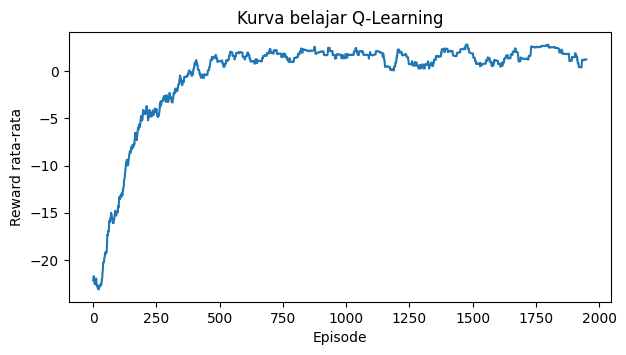

In [19]:
import random

UKURAN = 5
START, GOAL = (0, 0), (4, 4)
LUBANG = {(1, 3), (2, 1), (3, 3)}
AKSI = [(-1, 0), (1, 0), (0, -1), (0, 1)]       # atas, bawah, kiri, kanan
NAMA_AKSI = ["^", "v", "<", ">"]

def langkah(state, a):
    r, c = state
    dr, dc = AKSI[a]
    nr, nc = min(max(r + dr, 0), UKURAN - 1), min(max(c + dc, 0), UKURAN - 1)
    nxt = (nr, nc)
    if nxt == GOAL:
        return nxt, 10, True
    if nxt in LUBANG:
        return nxt, -10, True
    return nxt, -1, False

Q = np.zeros((UKURAN, UKURAN, len(AKSI)))
alpha, gamma = 0.1, 0.95
epsilon, eps_min, eps_decay = 1.0, 0.05, 0.995
EPISODE = 2000
riwayat_reward = []

random.seed(RANDOM_STATE)
for ep in range(EPISODE):
    s, selesai, total = START, False, 0
    for _ in range(100):
        if random.random() < epsilon:
            a = random.randrange(len(AKSI))            # eksplorasi
        else:
            a = int(np.argmax(Q[s]))                  # eksploitasi
        s2, r, selesai = langkah(s, a)
        Q[s][a] += alpha * (r + gamma * np.max(Q[s2]) - Q[s][a])
        s, total = s2, total + r
        if selesai:
            break
    epsilon = max(eps_min, epsilon * eps_decay)
    riwayat_reward.append(total)

# Kurva belajar (rata-rata bergerak 50 episode)
rata = np.convolve(riwayat_reward, np.ones(50) / 50, mode="valid")
plt.figure(figsize=(7, 3.5))
plt.plot(rata)
plt.xlabel("Episode"); plt.ylabel("Reward rata-rata")
plt.title("Kurva belajar Q-Learning")
plt.show()

In [20]:
print("Policy (S = start, G = goal, X = lubang):\n")
for r in range(UKURAN):
    baris = ""
    for c in range(UKURAN):
        if (r, c) == START: baris += " S "
        elif (r, c) == GOAL: baris += " G "
        elif (r, c) in LUBANG: baris += " X "
        else: baris += f" {NAMA_AKSI[int(np.argmax(Q[r, c]))]} "
    print(baris)

# Jalankan agen dengan policy terlatih
s, jalur = START, [START]
for _ in range(30):
    s, _, selesai = langkah(s, int(np.argmax(Q[s])))
    jalur.append(s)
    if selesai:
        break
print("\nJalur agen:", jalur)

Policy (S = start, G = goal, X = lubang):

 S  >  v  >  v 
 v  >  v  X  v 
 v  X  v  >  v 
 >  >  v  X  v 
 >  >  >  >  G 

Jalur agen: [(0, 0), (1, 0), (2, 0), (3, 0), (3, 1), (3, 2), (4, 2), (4, 3), (4, 4)]


In [21]:
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.datasets import load_digits

digits = load_digits()
Xd, yd = digits.data, digits.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    Xd, yd, test_size=0.3, stratify=yd, random_state=RANDOM_STATE)

# Sembunyikan 90% label pada data latih
rng = np.random.RandomState(RANDOM_STATE)
y_semi = yd_train.copy()
tak_berlabel = rng.rand(len(y_semi)) < 0.90
y_semi[tak_berlabel] = -1
print(f"Berlabel: {(y_semi != -1).sum()} | Tidak berlabel: {(y_semi == -1).sum()}")

dasar = SVC(probability=True, gamma=0.001, random_state=RANDOM_STATE)

# 1) Supervised hanya dengan data berlabel
sup = SVC(gamma=0.001, random_state=RANDOM_STATE).fit(Xd_train[y_semi != -1], y_semi[y_semi != -1])

# 2) Self-training memakai data berlabel + tidak berlabel
self_train = SelfTrainingClassifier(dasar, threshold=0.8).fit(Xd_train, y_semi)

print(f"Akurasi supervised (10% label) : {sup.score(Xd_test, yd_test):.3f}")
print(f"Akurasi self-training          : {self_train.score(Xd_test, yd_test):.3f}")

Berlabel: 131 | Tidak berlabel: 1126
Akurasi supervised (10% label) : 0.917
Akurasi self-training          : 0.946
